# 01211373 : Machine Learning and Programming for Industry

## Convolutional Neural Networks (CNN)

The materials from this notebook is extracted from Chapter 14 of [1].

**Topics :**

* Convolution operations in one and two dimensions
* The building blocks of CNN architectures
* Implementing deep CNNs in PyTorch
* Data augmentation techniques for improving the generalization performance
* Implementing a facial CNN classifier for recognizing if someone is smiling or not


### The building blocks of CNNs

CNNs are a family of models that were originally inspired by how the visual cortex of the human
brain works when recognizing objects. The development of CNNs goes back to the 1990s, when Yann
LeCun and his colleagues proposed a novel NN architecture for classifying handwritten digits from
images [2].

<span style="background-color: #e0e0e0">
The human visual cortex
The original discovery of how the visual cortex of our brain functions was made by David
H. Hubel and Torsten Wiesel in 1959, when they inserted a microelectrode into the primary
visual cortex of an anesthetized cat. They observed that neurons respond differently after
projecting different patterns of light in front of the cat. This eventually led to the discovery
of the different layers of the visual cortex. While the primary layer mainly detects edges and
straight lines, higher-order layers focus more on extracting complex shapes and patterns.
</span>

Due to the outstanding performance of CNNs for image classification tasks, this particular type of
feedforward NN gained a lot of attention and led to tremendous improvements in machine learning
for computer vision. Several years later, in 2019, Yann LeCun received the Turing award (the most
prestigious award in computer science) for his contributions to the field of artificial intelligence (AI),
along with two other researchers, Yoshua Bengio and Geoffrey Hinton, whose names you encountered
in previous chapters.

In the following sections, we will discuss the broader concepts of CNNs and why convolutional architectures
are often described as “feature extraction layers.” Then, we will delve into the theoretical
definition of the type of convolution operation that is commonly used in CNNs and walk through
examples of computing convolutions in one and two dimensions.

#### Understanding CNNs and feature hierarchies

Successfully extracting **salient (relevant) features** is key to the performance of any machine learning
algorithm, and traditional machine learning models rely on input features that may come from a
domain expert or are based on computational feature extraction techniques.

Certain types of NNs, such as CNNs, can automatically learn the features from raw data that are most
useful for a particular task. For this reason, it’s common to consider CNN layers as feature extractors:
the early layers (those right after the input layer) extract low-level features from raw data, and the
later layers (often **fully connected layers**, as in a **multilayer perceptron (MLP)**) use these features to
predict a continuous target value or class label.

Certain types of multilayer NNs, and in particular, deep CNNs, construct a so-called feature hierarchy
by combining the low-level features in a layer-wise fashion to form high-level features. For example,
if we’re dealing with images, then low-level features, such as edges and blobs, are extracted from the
earlier layers, which are combined to form high-level features. These high-level features can form
more complex shapes, such as the general contours of objects like buildings, cats, or dogs.

As you can see in Figure 14.1, a CNN computes feature maps from an input image, where each element
comes from a local patch of pixels in the input image.

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_01.png" width=800 />

Figure 14.1: Creating feature maps from an image (photo by Alexander Dummer on Unsplash)

This local patch of pixels is referred to as the local receptive field. CNNs will usually perform very
well on image-related tasks, and that’s largely due to two important ideas:

* Sparse connectivity: A single element in the feature map is connected to only a small patch
of pixels. (This is very different from connecting to the whole input image, as in the case of
MLPs. You may find it useful to look back and compare how we implemented a fully connected
network that connected to the whole image in Chapter 11, Implementing a Multilayer Artificial
Neural Network from Scratch.)
* Parameter sharing: The same weights are used for different patches of the input image.

As a direct consequence of these two ideas, replacing a conventional, fully connected MLP with a
convolution layer substantially decreases the number of weights (parameters) in the network, and
we will see an improvement in the ability to capture salient features. In the context of image data, it
makes sense to assume that nearby pixels are typically more relevant to each other than pixels that
are far away from each other.

Typically, CNNs are composed of several convolutional and subsampling layers that are followed
by one or more fully connected layers at the end. The fully connected layers are essentially an MLP,
where every input unit, i, is connected to every output unit, j, with weight wij (which we covered in
more detail in Chapter 11).

Please note that subsampling layers, commonly known as pooling layers, do not have any learnable
parameters; for instance, there are no weights or bias units in pooling layers. However, both the
convolutional and fully connected layers have weights and biases that are optimized during training.

In the following sections, we will study convolutional and pooling layers in more detail and see how
they work. To understand how convolution operations work, let’s start with a convolution in one
dimension, which is sometimes used for working with certain types of sequence data, such as text.
After discussing one-dimensional convolutions, we will work through the typical two-dimensional
ones that are commonly applied to two-dimensional images.

#### Performing discrete convolutions 

A discrete convolution (or simply convolution) is a fundamental operation in a CNN. Therefore, it’s
important to understand how this operation works. In this section, we will cover the mathematical
definition and discuss some of the naive algorithms to compute convolutions of one-dimensional
tensors (vectors) and two-dimensional tensors (matrices).

Please note that the formulas and descriptions in this section are solely for understanding how convolution
operations in CNNs work. Indeed, much more efficient implementations of convolutional
operations already exist in packages such as PyTorch, as you will see later in this chapter.

<hr>

**Mathematical notation** 

In this chapter, we will use subscript to denote the size of a multidimensional array (tensor);
for example, $A_{n_1 \times n_2}$ is a two-dimensional array of size $n_1 \times n_2$. We use brackets, [ ], to
denote the indexing of a multidimensional array. For example, $A[i, j]$ refers to the element
at index $i, j$ of matrix $A$. Furthermore, note that we use a special symbol, ∗ , to denote the
convolution operation between two vectors or matrices, which is not to be confused with
the multiplication operator, *, in Python.

<hr>

#### Discrete convolutions in one dimension

Let’s start with some basic definitions and notations that we are going to use. A discrete convolution
for two vectors, $x$ and $w$, is denoted by $y = x*w$ in which vector $x$ is our input (sometimes called
signal) and $w$ is called the filter or kernel. A discrete convolution is mathematically defined as follows
$$
y = x*w \rightarrow y[i] = \sum_{k=-\infty}^{+\infty}x[i-k]w[k]
$$
As mentioned earlier, the brackets, [ ], are used to denote the indexing for vector elements. The index,
$i$, runs through each element of the output vector, $y$. There are two odd things in the preceding formula
that we need to clarify: –∞ to +∞ indices and negative indexing for $x$.



The fact that the sum runs through indices from –∞ to +∞ seems odd, mainly because in machine
learning applications, we always deal with finite feature vectors. For example, if $x$ has 10 features with
indices 0, 1, 2, ..., 8, 9, then indices –∞: –1 and 10: +∞ are out of bounds for $x$. Therefore, to correctly
compute the summation shown in the preceding formula, it is assumed that $x$ and $w$ are filled with
zeros. This will result in an output vector, $y$, that also has infinite size, with lots of zeros as well. Since
this is not useful in practical situations, $x$ is padded only with a finite number of zeros.
This process is called zero-padding or simply padding. Here, the number of zeros padded on each
side is denoted by $p$. An example padding of a one-dimensional vector, $x$, is shown in Figure 14.2:

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_02.png" width=700 />

Figure 14.2: An example of padding

Let’s assume that the original input, $x$, and filter, $w$, have $n$ and $m$ elements, respectively, where $m \le n$.
Therefore, the padded vector, $x^p$, has size $n + 2p$. The practical formula for computing a discrete convolution will change to the following:
$$
y = x*w \rightarrow y[i] = \sum_{k=0}^{m-1}x^p[i+m-k]w[k]
$$
Now that we have solved the infinite index issue, the second issue is indexing $x$ with $i + m – k$. The
important point to notice here is that $x$ and $w$ are indexed in different directions in this summation.
Computing the sum with one index going in the reverse direction is equivalent to computing the sum
with both indices in the forward direction after flipping one of those vectors, $x$ or $w$, after they are
padded. Then, we can simply compute their dot product. Let’s assume we flip (rotate) the filter, $w$, to
get the rotated filter, $w^r$. Then, the dot product, $x[i: i + m].w^r$, is computed to get one element, $y[i]$, where
$x[i: i + m]$ is a patch of $x$ with size $m$. This operation is repeated like in a sliding window approach to get all the output elements.

The following figure provides an example with $x = [3, 2, 1, 7, 1, 2, 5, 4]$ and $w = [1/2, 3/4, 1, 1/4]$ so that the first three output elements are computed

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_03.png" width=800 />

Figure 14.3: The steps for computing a discrete convolution

You can see in the preceding example that the padding size is zero $(p = 0)$. Notice that the rotated filter,
$w^r$, is shifted by two cells each time we shift. This shift is another hyperparameter of a convolution,
the stride, $s$. In this example, the stride is two, $s = 2$. Note that the stride has to be a positive number
smaller than the size of the input vector. We will talk more about padding and strides in the next section.

<hr>

**Cross-correlation**

Cross-correlation (or simply correlation) between an input vector and a filter is denoted
by $y = x*w$ and is very much like a sibling of a convolution, with a small difference: in
cross-correlation, the multiplication is performed in the same direction. Therefore, it
is not a requirement to rotate the filter matrix, $w$, in each dimension. Mathematically, cross-correlation is defined as follows:
$$
y = x*w \rightarrow y[i] = \sum_{k=-\infty}^{\infty}x[i+k]w[k]
$$
The same rules for padding and stride may be applied to cross-correlation as well. Note
that most deep learning frameworks (including PyTorch) implement cross-correlation
but refer to it as convolution, which is a common convention in the deep learning field.

<hr>

#### Padding inputs to control the size of the output feature maps

So far, we’ve only used zero-padding in convolutions to compute finite-sized output vectors. Technically,
padding can be applied with any $p \ge 0$ . Depending on the choice of $p$, boundary cells may be treated
differently than the cells located in the middle of $x$.

Now, consider an example where $n = 5$ and $m = 3$. Then, with $p = 0, x[0]$ is only used in computing one
output element (for instance, $y[0]$), while $x[1]$ is used in the computation of two output elements (for
instance, $y[0]$ and $y[1]$). So, you can see that this different treatment of elements of $x$ can artificially
put more emphasis on the middle element, $x[2]$, since it has appeared in most computations. We can
avoid this issue if we choose $p = 2$, in which case, each element of $x$ will be involved in computing
three elements of $y$.

Furthermore, the size of the output, $y$, also depends on the choice of the padding strategy we use.

There are three modes of padding that are commonly used in practice: full, same, and valid.

In full mode, the padding parameter, $p$, is set to $p = m – 1$. Full padding increases the dimensions of
the output; thus, it is rarely used in CNN architectures.

The same padding mode is usually used to ensure that the output vector has the same size as the input
vector, $x$. In this case, the padding parameter, $p$, is computed according to the filter size, along with
the requirement that the input size and output size are the same.

Finally, computing a convolution in valid mode refers to the case where $p = 0$ (no padding).

Figure 14.4 illustrates the three different padding modes for a simple 5×5 pixel input with a kernel
size of 3×3 and a stride of 1:

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_04.png" width=800 />

Figure 14.4: The three modes of padding

The most commonly used padding mode in CNNs is same padding. One of its advantages over the
other padding modes is that same padding preserves the size of the vector—or the height and width
of the input images when we are working on image-related tasks in computer vision—which makes
designing a network architecture more convenient.

One big disadvantage of valid padding versus full and same padding is that the volume of the tensors
will decrease substantially in NNs with many layers, which can be detrimental to the network’s performance.
In practice, you should preserve the spatial size using same padding for the convolutional
layers and decrease the spatial size via pooling layers or convolutional layers with stride 2 instead,
as described in [3].

As for full padding, its size results in an output larger than the input size. Full padding is usually used
in signal processing applications where it is important to minimize boundary effects. However, in a
deep learning context, boundary effects are usually not an issue, so we rarely see full padding being
used in practice.

#### Determining the size of the convolution output

The output size of a convolution is determined by the total number of times that we shift the filter,
w, along the input vector. Let’s assume that the input vector is of size $n$ and the filter is of size $m$.
Then, the size of the output resulting from $y = x*w$ , with padding $p$ and stride $s$, would be determined as follows:
$$
o = \bigg\lfloor \frac{n+2p-m}{s} \bigg\rfloor + 1 
$$
Here, $\lfloor . \rfloor$ denotes the *floor* operation.

<hr>

**The floor operation** 

The floor operation returns the largest integer that is equal to or smaller than the input, for example:
<pre>
floor(1.77) = ⌊1.77⌋ = 1
</pre>

<hr>

Finally, in order to learn how to compute convolutions in one dimension, a naive implementation is
shown in the following code block, and the results are compared with the numpy.convolve function.
The code is as follows:

In [1]:
import torch
import numpy as np

print('PyTorch version:', torch.__version__)
print('NumPy version: ', np.__version__)

PyTorch version: 2.8.0
NumPy version:  2.3.1


In [2]:
def conv1d(x, w, p=0, s=1):
    w_rot = np.array(w[::-1])
    x_padded = np.array(x)
    if p > 0:
        zero_pad = np.zeros(shape=p)
        x_padded = np.concatenate(
            [zero_pad, x_padded, zero_pad])
    res = []
    for i in range(0, (int((len(x_padded) - len(w_rot))/s) + 1) * s, s):
        res.append(np.sum(
            x_padded[i:i + w_rot.shape[0]] * w_rot))
    return np.array(res)


## Testing:
x = [1, 3, 2, 4, 5, 6, 1, 3]
w = [1, 0, 3, 1, 2]

print('Conv1d Implementation:',
      conv1d(x, w, p=2, s=1))

print('Numpy Results:',
      np.convolve(x, w, mode='same')) 

Conv1d Implementation: [ 5. 14. 16. 26. 24. 34. 19. 22.]
Numpy Results: [ 5 14 16 26 24 34 19 22]


So far, we have mostly focused on convolutions for vectors (1D convolutions). We started with the 1D 
case to make the concepts easier to understand. In the next section, we will cover 2D convolutions in 
more detail, which are the building blocks of CNNs for image-related tasks.
    
#### Performing a discrete convolution in 2D

The concepts you learned in the previous sections are easily extendible to 2D. When we deal with 2D 
inputs, such as a matrix, $x_{n_1 \times n_2}$
, and the filter matrix,$W_{m_1 \times m_2}$, where $m_1 \le n_1$ and $m_2 \le n_2$, then the 
matrix $Y = X*W$ is the result of a 2D convolution between $X$ and $W$. This is defined mathematically 
as follows
$$
Y = X*W \rightarrow Y[i,j] = \sum_{k_1 = -\infty}^{+\infty}\sum_{k_2 = -\infty}^{+\infty}X[i=k_1,j-k_2]W[k_1,k_2]
$$
Notice that if you omit one of the dimensions, the remaining formula is exactly the same as the one 
we used previously to compute the convolution in 1D. In fact, all the previously mentioned techniques, 
such as zero padding, rotating the filter matrix, and the use of strides, are also applicable to 2D convolutions, provided that they are extended to both dimensions independently. Figure 14.5 demonstrates 
the 2D convolution of an input matrix of size 8×8, using a kernel of size 3×3. The input matrix is padded 
with zeros with p = 1. As a result, the output of the 2D convolution will have a size of 8×8

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_05.png" width=700 />

Figure 14.5: The output of a 2D convolution

The following example illustrates the computation of a 2D convolution between an input matrix, $X_{3 \times 3}$, 
and a kernel matrix, $W_{3 \times 3}$, using padding $p = (1, 1)$ and stride $s = (2, 2)$. According to the specified padding, one layer of zeros is added on each side of the input matrix, which results in the padded matrix 
$X_{5 \times 5}^{padded}$, as follows

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_06.png" width=600 />

Figure 14.6: Computing a 2D convolution between an input and kernel matrix

With the preceding filter, the rotated filter will be
$$
W^T = \left[\begin{array}{ccc}
0.5 & 1 & 0.5 \\
0.1 & 0.4 & 0.3 \\
0.4 & 0.7 & 0.5
\end{array}\right]
$$
Note that this rotation is not the same as the transpose matrix. To get the rotated filter in NumPy, we 
can write $W_rot=W[::-1,::-1]$. Next, we can shift the rotated filter matrix along the padded input 
matrix, $X^{padded}$, like a sliding window, and compute the sum of the element-wise product, which is 
denoted by the ⨀ operator in Figure 14.7

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_07.png" width=800 />

Figure 14.7: Computing the sum of the element-wise product

The result will be the 2×2 matrix, $Y$.
Let’s also implement the 2D convolution according to the naive algorithm described. The scipy.signal
package provides a way to compute 2D convolution via the scipy.signal.convolve2d function

In [3]:
import scipy.signal

def conv2d(X, W, p=(0, 0), s=(1, 1)):
    W_rot = np.array(W)[::-1,::-1]
    X_orig = np.array(X)
    n1 = X_orig.shape[0] + 2*p[0]
    n2 = X_orig.shape[1] + 2*p[1]
    X_padded = np.zeros(shape=(n1, n2))
    X_padded[p[0]:p[0]+X_orig.shape[0],
    p[1]:p[1]+X_orig.shape[1]] = X_orig

    res = []
    for i in range(0, (int((X_padded.shape[0] -
                            W_rot.shape[0]) / s[0]) + 1) * s[0], s[0]):
        res.append([])
        for j in range(0, (int((X_padded.shape[1] -
                                W_rot.shape[1]) / s[1]) + 1) * s[1], s[1]):
            X_sub = X_padded[i:i + W_rot.shape[0],
                    j:j + W_rot.shape[1]]
            res[-1].append(np.sum(X_sub * W_rot))
    return(np.array(res))

X = [[1, 3, 2, 4], [5, 6, 1, 3], [1, 2, 0, 2], [3, 4, 3, 2]]
W = [[1, 0, 3], [1, 2, 1], [0, 1, 1]]

print('Conv2d Implementation:\n',
    conv2d(X, W, p=(1, 1), s=(1, 1)))

print('SciPy Results:\n',
    scipy.signal.convolve2d(X, W, mode='same'))


Conv2d Implementation:
 [[11. 25. 32. 13.]
 [19. 25. 24. 13.]
 [13. 28. 25. 17.]
 [11. 17. 14.  9.]]
SciPy Results:
 [[11 25 32 13]
 [19 25 24 13]
 [13 28 25 17]
 [11 17 14  9]]


<hr>

**Efficient algorithms for computing convolution**

We provided a naive implementation to compute a 2D convolution for the purpose of 
understanding the concepts. However, this implementation is very inefficient in terms of 
memory requirements and computational complexity. Therefore, it should not be used 
in real-world NN applications.

One aspect is that the filter matrix is actually not rotated in most tools like PyTorch. 
Moreover, in recent years, much more efficient algorithms have been developed that use the 
Fourier transform to compute convolutions. It is also important to note that in the context 
of NNs, the size of a convolution kernel is usually much smaller than the size of the input 
image.
For example, modern CNNs usually use kernel sizes such as 1×1, 3×3, or 5×5, for which efficient 
algorithms have been designed that can carry out the convolutional operations much 
more efficiently, such as Winograd’s minimal filtering algorithm. These algorithms are 
beyond the scope of this book, but if you are interested in learning more, you can read 
the manuscript Fast Algorithms for Convolutional Neural Networks by Andrew Lavin and Scott 
Gray, 2015, which is freely available at https://arxiv.org/abs/1509.09308.

<hr>

In the next section, we will discuss subsampling or pooling, which is another important operation 
often used in CNNs.

#### Subsampling layers

Subsampling is typically applied in two forms of pooling operations in CNNs: **max-pooling** and 
**mean-pooling** (also known as **average-pooling**). The pooling layer is usually denoted by $P_{n_1 \times n_2}$
. Here, the subscript determines the size of the neighborhood (the number of adjacent pixels in each dimension) 
where the max or mean operation is performed. We refer to such a neighborhood as the pooling size.

The operation is described in Figure 14.8. Here, max-pooling takes the maximum value from a neighborhood of pixels, and mean-pooling computes their average

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_08.png" width=700 />

Figure 14.8: An example of max-pooling and mean-pooling

The advantage of pooling is twofold:

* Pooling (max-pooling) introduces a local invariance. This means that small changes in a local 
neighborhood do not change the result of max-pooling. Therefore, it helps with generating 
features that are more robust to noise in the input data. Refer to the following example, which 
shows that the max-pooling of two different input matrices, $X_1$ and $X_2$, results in the same output:

<img src="https://raw.githubusercontent.com/dewdotninja/mlpi/refs/heads/main/figures/maxpooling_same_output.png" width=600 />

* Pooling decreases the size of features, which results in higher computational efficiency. Furthermore, reducing the number of features may reduce the degree of overfitting as well. 

<hr>

**Overlapping versus non-overlapping pooling** 

Traditionally, pooling is assumed to be non-overlapping. Pooling is typically performed 
on non-overlapping neighborhoods, which can be done by setting the stride parameter 
equal to the pooling size. For example, a non-overlapping pooling layer, $P_{n_1 \times n_2}$
, requires 
a stride parameter $s = (n_1, n_2)$. On the other hand, overlapping pooling occurs if the stride 
is smaller than the pooling size. An example where overlapping pooling is used in a convolutional network is described in [4].

<hr>

While pooling is still an essential part of many CNN architectures, several CNN architectures have also 
been developed without using pooling layers. Instead of using pooling layers to reduce the feature 
size, researchers use convolutional layers with a stride of 2.

In a sense, you can think of a convolutional layer with stride 2 as a pooling layer with learnable weights. 
If you are interested in an empirical comparison of different CNN architectures developed with and 
without pooling layers, we recommend reading the research article [3]. 

### Putting everything together – implementing a CNN

So far, you have learned about the basic building blocks of CNNs. The concepts illustrated in this chapter are not really more difficult than traditional multilayer NNs. We can say that the most important 
operation in a traditional NN is matrix multiplication. For instance, we use matrix multiplications to 
compute the pre-activations (or net inputs), as in $z = Wx + b$. Here, $x$ is a column vector ($\mathbb{R}^{n \times 1}$ matrix) 
representing pixels, and $W$ is the weight matrix connecting the pixel inputs to each hidden unit.

In a CNN, this operation is replaced by a convolution operation, as in $Z = W*X + b$, where $X$ is a 
matrix representing the pixels in a height×width arrangement. In both cases, the pre-activations are 
passed to an activation function to obtain the activation of a hidden unit, $A = \sigma(Z)$, where $\sigma$ is the 
activation function. Furthermore, you will recall that subsampling is another building block of a CNN, 
which may appear in the form of pooling, as was described in the previous section.

#### Working with multiple input or color channels

An input to a convolutional layer may contain one or more 2D arrays or matrices with dimensions $N_1 \times N_2$
(for example, the image height and width in pixels). These $N_1 \times N_2$ matrices are called channels. Conventional implementations of convolutional layers expect a rank-3 tensor representation as an input, for 
example, a three-dimensional array, $X_{N_1 \times N_2 \times C_{in}}$, where $C_{in}$ is the number of input channels. For example, 
let’s consider images as input to the first layer of a CNN. If the image is colored and uses the RGB color 
mode, then $C_{in} = 3$ (for the red, green, and blue color channels in RGB). However, if the image is in grayscale, then we have $C_{in} = 1$, because there is only one channel with the grayscale pixel intensity values.

<hr>

**Reading an image file** 

When we work with images, we can read images into NumPy arrays using the uint8
(unsigned 8-bit integer) data type to reduce memory usage compared to 16-bit, 32-bit, or 
64-bit integer types, for example.

Unsigned 8-bit integers take values in the range [0, 255], which are sufficient to store the 
pixel information in RGB images, which also take values in the same range.

In Chapter 12, Parallelizing Neural Network Training with PyTorch, you saw that PyTorch 
provides a module for loading/storing and manipulating images via torchvision. Let’s 
recap how to read an image (this example RGB image is located in the code bundle folder 
that is provided with this chapter):

In [4]:
# Note : running this cell caused error on Windows. Fix by 
# !pip uninstall pillow
# !pip install pillow==10.4.2
# You also need to put example-image.png from text github (ch14) in the current directory
import torch
from torchvision.io import read_image
 
img = read_image('example-image.png') 
 
print('Image shape:', img.shape)
print('Number of channels:', img.shape[0])
print('Image data type:', img.dtype)
print(img[:, 100:102, 100:102])

Image shape: torch.Size([3, 252, 221])
Number of channels: 3
Image data type: torch.uint8
tensor([[[179, 182],
         [180, 182]],

        [[134, 136],
         [135, 137]],

        [[110, 112],
         [111, 113]]], dtype=torch.uint8)


Note that with torchvision, the input and output image tensors are in the format of 
Tensor[channels, image_height, image_width].

<hr>

Now that you are familiar with the structure of input data, the next question is, how can we incorporate 
multiple input channels in the convolution operation that we discussed in the previous sections? The 
answer is very simple: we perform the convolution operation for each channel separately and then 
add the results together using the matrix summation. The convolution associated with each channel 
(c) has its own kernel matrix as $W[:, :, c]$.

The total pre-activation result is computed in the following formula 

<img src="https://raw.githubusercontent.com/dewdotninja/mlpi/refs/heads/main/figures/p466_1.png" width=600 />

The final result, $A$, is a feature map. Usually, a convolutional layer of a CNN has more than one feature 
map. If we use multiple feature maps, the kernel tensor becomes four-dimensional: $width \times height \times $C_{in} \times C_{out}$. 
Here, $width \times height$ is the kernel size, $C_in$ is the number of input channels, and $C_out$ is the number of 
output feature maps. So, now let’s include the number of output feature maps in the preceding formula 
and update it, as follows

<img src="https://raw.githubusercontent.com/dewdotninja/mlpi/refs/heads/main/figures/p466_2.png" width=600 />

To conclude our discussion of computing convolutions in the context of NNs, let’s look at the example 
in Figure 14.9, which shows a convolutional layer, followed by a pooling layer. In this example, there 
are three input channels. The kernel tensor is four-dimensional. Each kernel matrix is denoted as 
m1×m2, and there are three of them, one for each input channel. Furthermore, there are five such 
kernels, accounting for five output feature maps. Finally, there is a pooling layer for subsampling the 
feature maps

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_09.png" width=800 />

Figure 14.9: Implementing a CNN

<hr>

**How many trainable parameters exist in the preceding example?** 

To illustrate the advantages of convolution, parameter sharing, and sparse connectivity, 
let’s work through an example. The convolutional layer in the network shown in Figure 
14.9 is a four-dimensional tensor. So, there are m1×m2×3×5 parameters associated with the 
kernel. Furthermore, there is a bias vector for each output feature map of the convolutional layer. 
Thus, the size of the bias vector is 5. Pooling layers do not have any (trainable) 
parameters; therefore, we can write the following:
$$
m_1 × m_2 × 3 × 5 + 5
$$
If the input tensor is of size $n_1×n_2×3$, assuming that the convolution is performed with the 
same-padding mode, then the size of the output feature maps would be $n_1 × n_2 × 5$.
Note that if we use a fully connected layer instead of a convolutional layer, this number 
will be much larger. In the case of a fully connected layer, the number of parameters 
for the weight matrix to reach the same number of output units would have been as 
follows:
$$
(n_1 × n_2 × 3) × (n_1 × n_2 × 5) = (n_1 × n_2)^2 × 3 × 5
$$
In addition, the size of the bias vector is $n_1 × n_2 × 5$ (one bias element for each output unit). 
Given that $m_1 \lt n_1$ and $m_2 \lt n_2$, we can see that the difference in the number of trainable 
parameters is significant.

<hr>

Lastly, as was already mentioned, the convolution operations typically are carried out by treating an 
input image with multiple color channels as a stack of matrices; that is, we perform the convolution 
on each matrix separately and then add the results, as was illustrated in the previous figure. However, 
convolutions can also be extended to 3D volumes if you are working with 3D datasets, for example, 
as shown in the paper [5].

In the next section, we will talk about how to regularize an NN.

#### Regularizing an NN with L2 regularization and dropout

Choosing the size of a network, whether we are dealing with a traditional (fully connected) NN or a 
CNN, has always been a challenging problem. For instance, the size of a weight matrix and the number 
of layers need to be tuned to achieve a reasonably good performance.

You will recall from Chapter 13, Going Deeper – The Mechanics of PyTorch, that a simple network without 
a hidden layer could only capture a linear decision boundary, which is not sufficient for dealing with 
an exclusive or (or XOR) or similar problem. The capacity of a network refers to the level of complexity of the function that it can learn to approximate. Small networks, or networks with a relatively 
small number of parameters, have a low capacity and are therefore likely to underfit, resulting in 
poor performance, since they cannot learn the underlying structure of complex datasets. However, 
very large networks may result in overfitting, where the network will memorize the training data and 
do extremely well on the training dataset while achieving a poor performance on the held-out test 
dataset. When we deal with real-world machine learning problems, we do not know how large the 
network should be a priori.

One way to address this problem is to build a network with a relatively large capacity (in practice, 
we want to choose a capacity that is slightly larger than necessary) to do well on the training dataset. 
Then, to prevent overfitting, we can apply one or multiple regularization schemes to achieve good 
generalization performance on new data, such as the held-out test dataset.

In Chapters 3 and 4, we covered L1 and L2 regularization. Both techniques can prevent or reduce the 
effect of overfitting by adding a penalty to the loss that results in shrinking the weight parameters 
during training. While both L1 and L2 regularization can be used for NNs as well, with L2 being the 
more common choice of the two, there are other methods for regularizing NNs, such as dropout, 
which we discuss in this section. But before we move on to discussing dropout, to use L2 regularization 
within a convolutional or fully connected network (recall, fully connected layers are implemented 
via torch.nn.Linear in PyTorch), you can simply add the L2 penalty of a particular layer to the loss 
function in PyTorch, as follows:

In [5]:
import torch.nn as nn
loss_func = nn.BCELoss()
loss = loss_func(torch.tensor([0.9]), torch.tensor([1.0]))
l2_lambda = 0.001

conv_layer = nn.Conv2d(in_channels=3, out_channels=5, kernel_size=5)
l2_penalty = l2_lambda * sum([(p**2).sum() for p in conv_layer.parameters()])
loss_with_penalty = loss + l2_penalty

linear_layer = nn.Linear(10, 16)
l2_penalty = l2_lambda * sum([(p**2).sum() for p in linear_layer.parameters()])
loss_with_penalty = loss + l2_penalty

<hr>

**Weight decay versus L2 regularization**

An alternative way to use L2 regularization is by setting the weight_decay parameter in 
a PyTorch optimizer to a positive value, for example:
```python
optimizer = torch.optim.SGD(
 model.parameters(),
 weight_decay=l2_lambda,
 ...
)
```

While L2 regularization and weight_decay are not strictly identical, it can be shown that 
they are equivalent when using stochastic gradient descent (SGD) optimizers. Interested 
readers can find more information in the article [6]

<hr>

In recent years, dropout has emerged as a popular technique for regularizing (deep) NNs to avoid 
overfitting, thus improving the generalization performance [7] . Dropout is usually applied to the hidden units of 
higher layers and works as follows: during the training phase of an NN, a fraction of the hidden units 
is randomly dropped at every iteration with probability pdrop (or keep probability pkeep = 1 – pdrop). This 
dropout probability is determined by the user and the common choice is p = 0.5, as discussed in [7]. 
When dropping a certain fraction of input neurons, the weights associated with the remaining neurons are rescaled to account for the 
missing (dropped) neurons.

The effect of this random dropout is that the network is forced to learn a redundant representation 
of the data. Therefore, the network cannot rely on the activation of any set of hidden units, since 
they may be turned off at any time during training, and is forced to learn more general and robust 
patterns from the data.

This random dropout can effectively prevent overfitting. Figure 14.10 shows an example of applying 
dropout with probability $p = 0.5$ during the training phase, whereby half of the neurons will become 
inactive randomly (dropped units are selected randomly in each forward pass of training). However, 
during prediction, all neurons will contribute to computing the pre-activations of the next layer

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_10.png" width=800 />

Figure 14.10: Applying dropout during the training phase

As shown here, one important point to remember is that units may drop randomly during training 
only, whereas for the evaluation (inference) phase, all the hidden units must be active (for instance, 
$p_{drop} = 0$ or $p_{keep} = 1$). To ensure that the overall activations are on the same scale during training and 
prediction, the activations of the active neurons have to be scaled appropriately (for example, by halving 
the activation if the dropout probability was set to $p = 0.5$).

However, since it is inconvenient to always scale activations when making predictions, PyTorch and 
other tools scale the activations during training (for example, by doubling the activations if the dropout 
probability was set to $p = 0.5$). This approach is commonly referred to as inverse dropout.
While the relationship is not immediately obvious, dropout can be interpreted as the consensus (averaging) of an ensemble of models. As discussed in Chapter 7, Combining Different Models for Ensemble 
Learning, in ensemble learning, we train several models independently. During prediction, we then 
use the consensus of all the trained models. We already know that model ensembles are known to 
perform better than single models. In deep learning, however, both training several models and 
collecting and averaging the output of multiple models is computationally expensive. Here, dropout 
offers a workaround, with an efficient way to train many models at once and compute their average 
predictions at test or prediction time.

As mentioned previously, the relationship between model ensembles and dropout is not immediately
obvious. However, consider that in dropout, we have a different model for each mini-batch (due to
setting the weights to zero randomly during each forward pass).

Then, via iterating over the mini-batches, we essentially sample over $M = 2^h$
 models, where $h$ is the 
number of hidden units.

The restriction and aspect that distinguishes dropout from regular ensembling, however, is that we 
share the weights over these “different models,” which can be seen as a form of regularization. Then, 
during “inference” (for instance, predicting the labels in the test dataset), we can average over all these 
different models that we sampled over during training. This is very expensive, though.

Then, averaging the models, that is, computing the geometric mean of the class-membership probability that is returned by a model, $i$, can be computed as follows
$$
p_{Ensemble} = \left[\prod_{j=1}^M p^{(i)} \right]^{\frac{1}{M}}
$$
Now, the trick behind dropout is that this geometric mean of the model ensembles (here, $M$ models) 
can be approximated by scaling the predictions of the last (or final) model sampled during training 
by a factor of $1/(1 – p)$, which is much cheaper than computing the geometric mean explicitly using 
the previous equation. (In fact, the approximation is exactly equivalent to the true geometric mean 
if we consider linear models.)

#### Loss functions for classification

In Chapter 12, Parallelizing Neural Network Training with PyTorch, we saw different activation functions, 
such as ReLU, sigmoid, and tanh. Some of these activation functions, like ReLU, are mainly used in the 
intermediate (hidden) layers of an NN to add non-linearities to our model. But others, like sigmoid (for 
binary) and softmax (for multiclass), are added at the last (output) layer, which results in 
class-membership probabilities as the output of the model. If the sigmoid or softmax activations are not included at 
the output layer, then the model will compute the logits instead of the class-membership probabilities.

Focusing on classification problems here, depending on the type of problem (binary versus multiclass) 
and the type of output (logits versus probabilities), we should choose the appropriate loss function 
to train our model. **Binary cross-entropy** is the loss function for a binary classification (with a single 
output unit), and **categorical cross-entropy** is the loss function for multiclass classification. In the 
torch.nn module, the categorical cross-entropy loss takes in ground truth labels as integers (for example, $y=2$, out of three classes, 0, 1, and 2). 

Figure 14.11 describes two loss functions available in torch.nn for dealing with both cases: binary 
classification and multiclass with integer labels. Each one of these two loss functions also has the 
option to receive the predictions in the form of logits or class-membership probabilities.

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_11.png" width=800 />

Figure 14.11: Two examples of loss functions in PyTorch

Please note that computing the cross-entropy loss by providing the logits, and not the class-membership probabilities, is usually preferred due to numerical stability reasons. For binary classification, 
we can either provide logits as inputs to the loss function nn.BCEWithLogitsLoss(), or compute the 
probabilities based on the logits and feed them to the loss function nn.BCELoss(). For multiclass 
classification, we can either provide logits as inputs to the loss function nn.CrossEntropyLoss(), or 
compute the log probabilities based on the logits and feed them to the negative log-likelihood loss 
function nn.NLLLoss().

The following code will show you how to use these loss functions with two different formats, where 
either the logits or class-membership probabilities are given as inputs to the loss functions:


In [6]:
####### Binary Cross-entropy
logits = torch.tensor([0.8])
probas = torch.sigmoid(logits)
target = torch.tensor([1.0])

bce_loss_fn = nn.BCELoss()
bce_logits_loss_fn = nn.BCEWithLogitsLoss()

print(f'BCE (w Probas): {bce_loss_fn(probas, target):.4f}')
print(f'BCE (w Logits): {bce_logits_loss_fn(logits, target):.4f}')

 
####### Categorical Cross-entropy
logits = torch.tensor([[1.5, 0.8, 2.1]])
probas = torch.softmax(logits, dim=1)
target = torch.tensor([2])

cce_loss_fn = nn.NLLLoss()
cce_logits_loss_fn = nn.CrossEntropyLoss()

print(f'CCE (w Logits): {cce_logits_loss_fn(logits, target):.4f}')
print(f'CCE (w Probas): {cce_loss_fn(torch.log(probas), target):.4f}')

BCE (w Probas): 0.3711
BCE (w Logits): 0.3711
CCE (w Logits): 0.5996
CCE (w Probas): 0.5996


Note that sometimes, you may come across an implementation where a categorical cross-entropy 
loss is used for binary classification. Typically, when we have a binary classification task, the model 
returns a single output value for each example. We interpret this single model output as the probability of the positive class (for example, class 1), P(class = 1|x). In a binary classification problem, it 
is implied that P(class = 0|x)= 1 – P(class = 1|x); hence, we do not need a second output unit in order 
to obtain the probability of the negative class. However, sometimes practitioners choose to return 
two outputs for each training example and interpret them as probabilities of each class: P(class = 0|x) 
versus P(class = 1|x). Then, in such a case, using a softmax function (instead of the logistic sigmoid) 
to normalize the outputs (so that they sum to 1) is recommended, and categorical cross-entropy is 
the appropriate loss function.

#### Implementing a deep CNN using PyTorch

In Chapter 13, as you may recall, we solved the handwritten digit recognition problem using the torch.
nn module. You may also recall that we achieved about 95.6 percent accuracy using an NN with two 
linear hidden layers.

Now, let’s implement a CNN and see whether it can achieve a better predictive performance compared 
to the previous model for classifying handwritten digits. Note that the fully connected layers that we 
saw in Chapter 13 were able to perform well on this problem. However, in some applications, such 
as reading bank account numbers from handwritten digits, even tiny mistakes can be very costly. 
Therefore, it is crucial to reduce this error as much as possible.

#### The multilayer CNN architecture

The architecture of the network that we are going to implement is shown in Figure 14.12. The inputs 
are 28×28 grayscale images. Considering the number of channels (which is 1 for grayscale images) 
and a batch of input images, the input tensor’s dimensions will be batchsize×28×28×1.

The input data goes through two convolutional layers that have a kernel size of 5×5. The first convolution has 32 output feature maps, and the second one has 64 output feature maps. Each convolution 
layer is followed by a subsampling layer in the form of a max-pooling operation, P2×2. Then a fully 
connected layer passes the output to a second fully connected layer, which acts as the final softmax
output layer. The architecture of the network that we are going to implement is shown in Figure 14.12

<img src="https://raw.githubusercontent.com/rasbt/machine-learning-book/refs/heads/main/ch14/figures/14_12.png" width=800 />

Figure 14.12: A deep CNN

The dimensions of the tensors in each layer are as follows:
* Input: [batchsize×28×28×1]
* Conv_1: [batchsize×28×28×32]
* Pooling_1: [batchsize×14×14×32]
* Conv_2: [batchsize×14×14×64]
* Pooling_2: [batchsize×7×7×64]
* FC_1: [batchsize×1024]
* FC_2 and softmax layer: [batchsize×10]

For the convolutional kernels, we are using stride=1 such that the input dimensions are preserved 
in the resulting feature maps. For the pooling layers, we are using kernel_size=2 to subsample the 
image and shrink the size of the output feature maps. We will implement this network using the 
PyTorch NN module.

#### Loading and preprocessing the data

First, we will load the MNIST dataset using the torchvision module and construct the training and 
test sets, as we did in Chapter 13

In [7]:
import torchvision 
from torchvision import transforms 
image_path = './'
transform = transforms.Compose([transforms.ToTensor()])

mnist_dataset = torchvision.datasets.MNIST(root=image_path, 
                                           train=True, 
                                           transform=transform, 
                                           download=True)

from torch.utils.data import Subset
mnist_valid_dataset = Subset(mnist_dataset, torch.arange(10000)) 
mnist_train_dataset = Subset(mnist_dataset, torch.arange(10000, len(mnist_dataset)))
mnist_test_dataset = torchvision.datasets.MNIST(root=image_path, 
                                           train=False, 
                                           transform=transform, 
                                           download=False)

100%|██████████| 9.91M/9.91M [00:05<00:00, 1.80MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 108kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 975kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.38MB/s]


The MNIST dataset comes with a pre-specified training and test dataset partitioning scheme, but we 
also want to create a validation split from the train partition. Hence, we used the first 10,000 training 
examples for validation. Note that the images are not sorted by class label, so we do not have to worry 
about whether those validation set images are from the same classes.

Next, we will construct the data loader with batches of 64 images for the training set and validation 
set, respectively

In [8]:
from torch.utils.data import DataLoader

batch_size = 64
torch.manual_seed(1)
train_dl = DataLoader(mnist_train_dataset, batch_size, shuffle=True)
valid_dl = DataLoader(mnist_valid_dataset, batch_size, shuffle=False)

The features we read are of values in the range [0, 1]. Also, we already converted the images to tensors.
The labels are integers from 0 to 9, representing ten digits. Hence, we don’t need to do any scaling or
further conversion.

Now, after preparing the dataset, we are ready to implement the CNN we just described.

#### Implementing a CNN using the torch.nn module

For implementing a CNN in PyTorch, we use the torch.nn Sequential class to stack different layers,
such as convolution, pooling, and dropout, as well as the fully connected layers. The torch.nn module
provides classes for each one: nn.Conv2d for a two-dimensional convolution layer; nn.MaxPool2d and
nn.AvgPool2d for subsampling (max-pooling and average-pooling); and nn.Dropout for regularization
using dropout. We will go over each of these classes in more detail.

#### Configuring CNN layers in PyTorch

Constructing a layer with the Conv2d class requires us to specify the number of output channels (which
is equivalent to the number of output feature maps, or the number of output filters) and kernel sizes.

In addition, there are optional parameters that we can use to configure a convolutional layer. The
most commonly used ones are the strides (with a default value of 1 in both x, y dimensions) and padding,
which controls the amount of implicit padding on both dimensions. Additional configuration
parameters are listed in the official documentation: https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html.

It is worth mentioning that usually, when we read an image, the default dimension for the channels
is the first dimension of the tensor array (or the second dimension considering the batch dimension).
This is called the NCHW format, where N stands for the number of images within the batch, C stands
for channels, and H and W stand for height and width, respectively.

Note that the Conv2D class assumes that inputs are in NCHW format by default. (Other tools, such as
TensorFlow, use NHWC format.) However, if you come across some data whose channels are placed
at the last dimension, you would need to swap the axes in your data to move the channels to the first
dimension (or the second dimension considering the batch dimension). After the layer is constructed,
it can be called by providing a four-dimensional tensor, with the first dimension reserved for a batch
of examples; the second dimension corresponds to the channel; and the other two dimensions are
the spatial dimensions.

As shown in the architecture of the CNN model that we want to build, each convolution layer is followed
by a pooling layer for subsampling (reducing the size of feature maps). The MaxPool2d and AvgPool2d
classes construct the max-pooling and average-pooling layers, respectively. The kernel_size argument
determines the size of the window (or neighborhood) that will be used to compute the max or
mean operations. Furthermore, the stride parameter can be used to configure the pooling layer, as
we discussed earlier.

Finally, the Dropout class will construct the dropout layer for regularization, with the argument $p$ that
denotes the drop probability $p_{drop}$, which is used to determine the probability of dropping the input
units during training, as we discussed earlier. When calling this layer, its behavior can be controlled
via model.train() and model.eval(), to specify whether this call will be made during training or
during the inference. When using dropout, alternating between these two modes is crucial to ensure
that it behaves correctly; for instance, nodes are only randomly dropped during training, not evaluation or inference.

#### Constructing a CNN in PyTorch

Now that you have learned about these classes, we can construct the CNN model that was shown in
the previous figure. In the following code, we will use the Sequential class and add the convolution
and pooling layers


In [10]:
model = nn.Sequential()
model.add_module('conv1', nn.Conv2d(in_channels=1, out_channels=32, kernel_size=5, padding=2))
model.add_module('relu1', nn.ReLU())        
model.add_module('pool1', nn.MaxPool2d(kernel_size=2))   
model.add_module('conv2', nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, padding=2))
model.add_module('relu2', nn.ReLU())        
model.add_module('pool2', nn.MaxPool2d(kernel_size=2))      



So far, we have added two convolution layers to the model. For each convolutional layer, we used a
kernel of size 5×5 and padding=2. As discussed earlier, using same padding mode preserves the spatial
dimensions (vertical and horizontal dimensions) of the feature maps such that the inputs and outputs
have the same height and width (and the number of channels may only differ in terms of the number
of filters used). As mentioned before, the spatial dimension of the output feature map is calculated by
$$
o = \bigg\lfloor \frac{n+2p-m}{s} \bigg\rfloor + 1 
$$
where $n$ is the spatial dimension of the input feature map, and $p, m,$ and $s$ denote the padding, kernel
size, and stride, respectively. We obtain $p = 2$ in order to achieve $o = i$.

The max-pooling layers with pooling size 2×2 and stride of 2 will reduce the spatial dimensions by
half. (Note that if the stride parameter is not specified in MaxPool2D, by default, it is set equal to the
pooling kernel size.)

While we can calculate the size of the feature maps at this stage manually, PyTorch provides a convenient
method to compute this for us


In [11]:
x = torch.ones((4, 1, 28, 28))
model(x).shape

torch.Size([4, 64, 7, 7])

By providing the input shape as a tuple (4, 1, 28, 28) (4 images within the batch, 1 channel, and
image size 28×28), specified in this example, we calculated the output to have a shape (4, 64, 7, 7),
indicating feature maps with 64 channels and a spatial size of 7×7. The first dimension corresponds
to the batch dimension, for which we used 4 arbitrarily.

The next layer that we want to add is a fully connected layer for implementing a classifier on top of
our convolutional and pooling layers. The input to this layer must have rank 2, that is, shape [batchsize
× input_units]. Thus, we need to flatten the output of the previous layers to meet this requirement
for the fully connected layer

In [12]:
model.add_module('flatten', nn.Flatten()) 

x = torch.ones((4, 1, 28, 28))
model(x).shape

torch.Size([4, 3136])

As the output shape indicates, the input dimensions for the fully connected layer are correctly set up.
Next, we will add two fully connected layers with a dropout layer in between

In [13]:
model.add_module('fc1', nn.Linear(3136, 1024)) 
model.add_module('relu3', nn.ReLU()) 
model.add_module('dropout', nn.Dropout(p=0.5)) 

model.add_module('fc2', nn.Linear(1024, 10)) 

The last fully connected layer, named 'fc2', has 10 output units for the 10 class labels in the MNIST
dataset. In practice, we usually use the sofmax activation to obtain the class-membership probabilities
of each input example, assuming that the classes are mutually exclusive, so the probabilities for
each example sum to 1. However, the softmax function is already used internally inside PyTorch’s
CrossEntropyLoss implementation, which is why don’t have to explicitly add it as a layer after the
output layer above. The following code will create the loss function and optimizer for the model.



In [14]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

<hr>

**The Adam optimizer** 

Note that in this implementation, we used the torch.optim.Adam class for training the
CNN model. The Adam optimizer is a robust, gradient-based optimization method suited
to nonconvex optimization and machine learning problems. Two popular optimization
methods inspired Adam: RMSProp and AdaGrad.
The key advantage of Adam is in the choice of update step size derived from the running
average of gradient moments. Please feel free to read more about the Adam optimizer
in the manuscript [8]. 

<hr>

Now we can train the model by defining the following function

In [16]:
# device = torch.device("cuda:0")
device = torch.device("cpu")
model = model.to(device) 

In [ ]:
def train(model, num_epochs, train_dl, valid_dl):
    loss_hist_train = [0] * num_epochs
    accuracy_hist_train = [0] * num_epochs
    loss_hist_valid = [0] * num_epochs
    accuracy_hist_valid = [0] * num_epochs
    for epoch in range(num_epochs):
        model.train()
        for x_batch, y_batch in train_dl:
            x_batch = x_batch.to(device) 
            y_batch = y_batch.to(device) 
            pred = model(x_batch)
            loss = loss_fn(pred, y_batch)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            loss_hist_train[epoch] += loss.item()*y_batch.size(0)
            is_correct = (torch.argmax(pred, dim=1) == y_batch).float()
            accuracy_hist_train[epoch] += is_correct.sum().cpu()

        loss_hist_train[epoch] /= len(train_dl.dataset)
        accuracy_hist_train[epoch] /= len(train_dl.dataset)
        
        model.eval()
        with torch.no_grad():
            for x_batch, y_batch in valid_dl:
                x_batch = x_batch.to(device) 
                y_batch = y_batch.to(device) 
                pred = model(x_batch)
                loss = loss_fn(pred, y_batch)
                loss_hist_valid[epoch] += loss.item()*y_batch.size(0) 
                is_correct = (torch.argmax(pred, dim=1) == y_batch).float() 
                accuracy_hist_valid[epoch] += is_correct.sum().cpu()

        loss_hist_valid[epoch] /= len(valid_dl.dataset)
        accuracy_hist_valid[epoch] /= len(valid_dl.dataset)
        
        print(f'Epoch {epoch+1} accuracy: {accuracy_hist_train[epoch]:.4f} val_accuracy: {accuracy_hist_valid[epoch]:.4f}')
    return loss_hist_train, loss_hist_valid, accuracy_hist_train, accuracy_hist_valid


Note that using the designated settings for training model.train() and evaluation model.eval() will
automatically set the mode for the dropout layer and rescale the hidden units appropriately so that
we do not have to worry about that at all. Next, we will train this CNN model and use the validation
dataset that we created for monitoring the learning progress

**Warning :** Running the cell below took about 15 minutes on my Mac M1 machine. If you have GPU, use it!

In [ ]:
torch.manual_seed(1)
num_epochs = 20
hist = train(model, num_epochs, train_dl, valid_dl)

Epoch 1 accuracy: 0.9491 val_accuracy: 0.9765
Epoch 2 accuracy: 0.9841 val_accuracy: 0.9841
Epoch 3 accuracy: 0.9891 val_accuracy: 0.9885
Epoch 4 accuracy: 0.9913 val_accuracy: 0.9900
Epoch 5 accuracy: 0.9933 val_accuracy: 0.9892
Epoch 6 accuracy: 0.9944 val_accuracy: 0.9886
Epoch 7 accuracy: 0.9951 val_accuracy: 0.9914
Epoch 8 accuracy: 0.9956 val_accuracy: 0.9886
Epoch 9 accuracy: 0.9963 val_accuracy: 0.9905
Epoch 10 accuracy: 0.9971 val_accuracy: 0.9895
Epoch 11 accuracy: 0.9968 val_accuracy: 0.9915
Epoch 12 accuracy: 0.9971 val_accuracy: 0.9900
Epoch 13 accuracy: 0.9981 val_accuracy: 0.9916
Epoch 14 accuracy: 0.9977 val_accuracy: 0.9913
Epoch 15 accuracy: 0.9978 val_accuracy: 0.9909
Epoch 16 accuracy: 0.9981 val_accuracy: 0.9914
Epoch 17 accuracy: 0.9978 val_accuracy: 0.9911
Epoch 18 accuracy: 0.9978 val_accuracy: 0.9903
Epoch 19 accuracy: 0.9986 val_accuracy: 0.9924
Epoch 20 accuracy: 0.9990 val_accuracy: 0.9913


Once the 20 epochs of training are finished, we can visualize the learning curves:

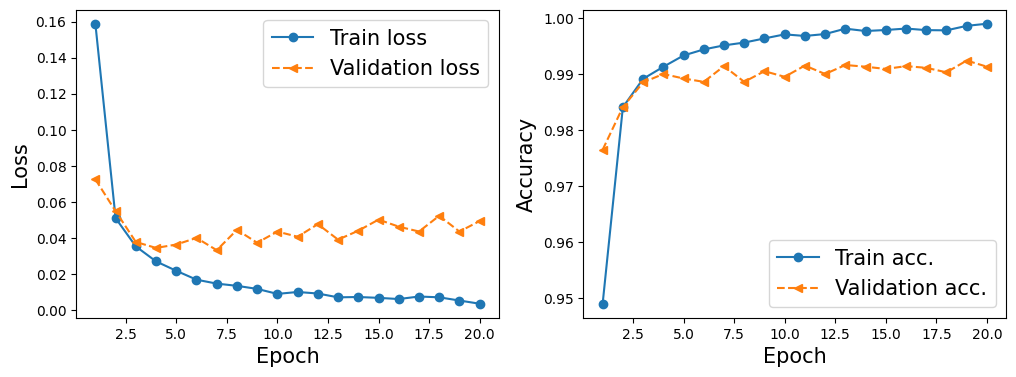

In [18]:
import matplotlib.pyplot as plt

x_arr = np.arange(len(hist[0])) + 1

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 2, 1)
ax.plot(x_arr, hist[0], '-o', label='Train loss')
ax.plot(x_arr, hist[1], '--<', label='Validation loss')
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Loss', size=15)
ax.legend(fontsize=15)
ax = fig.add_subplot(1, 2, 2)
ax.plot(x_arr, hist[2], '-o', label='Train acc.')
ax.plot(x_arr, hist[3], '--<', label='Validation acc.')
ax.legend(fontsize=15)
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Accuracy', size=15)
plt.show()

Figure 14.13: Loss and accuracy graphs for the training and validation data
    
Now, we evaluate the trained model on the test dataset

In [20]:
# torch.cuda.synchronize()
# model_cpu = model.cpu()
pred = model(mnist_test_dataset.data.unsqueeze(1) / 255.)
is_correct = (torch.argmax(pred, dim=1) == mnist_test_dataset.targets).float()
print(f'Test accuracy: {is_correct.mean():.4f}') 

Test accuracy: 0.9919


The CNN model achieves an accuracy of 99 percent. Remember that in Chapter 13, we got approximately
95 percent accuracy using only fully connected (instead of convolutional) layers.
Finally, we can get the prediction results in the form of class-membership probabilities and convert
them to predicted labels by using the torch.argmax function to find the element with the maximum
probability. We will do this for a batch of 12 examples and visualize the input and predicted labels

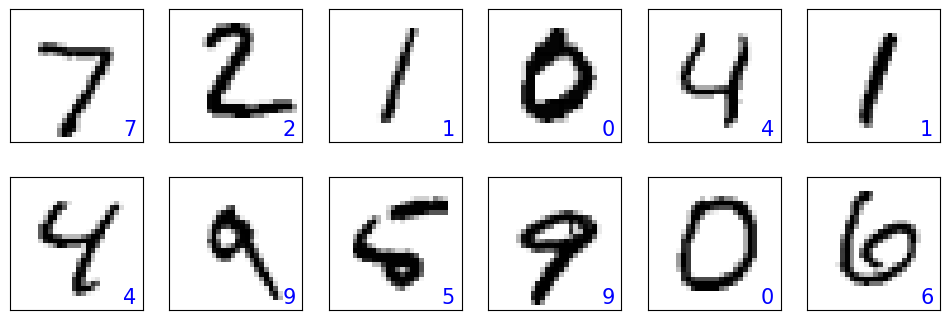

In [21]:
fig = plt.figure(figsize=(12, 4))
for i in range(12):
    ax = fig.add_subplot(2, 6, i+1)
    ax.set_xticks([]); ax.set_yticks([])
    img = mnist_test_dataset[i][0][0, :, :]
    pred = model(img.unsqueeze(0).unsqueeze(1)) # alternatively: mnist_test_dataset.data[i].float()
    y_pred = torch.argmax(pred)
    ax.imshow(img, cmap='gray_r')
    ax.text(0.9, 0.1, y_pred.item(), 
            size=15, color='blue',
            horizontalalignment='center',
            verticalalignment='center', 
            transform=ax.transAxes)

plt.show()

In this set of plotted examples, all the predicted labels are correct.

We leave the task of showing some of the misclassified digits, as we did in Chapter 11, Implementing a
Multilayer Artificial Neural Network from Scratch, as an exercise for the reader.

Running the cell below to save the model.

In [22]:
import os

if not os.path.exists('models'):
    os.mkdir('models')

path = 'models/mnist-cnn.ph'
torch.save(model, path)

#### Smile classification from face images using a CNN

In this section, we are going to implement a CNN for smile classification from face images using the
CelebA dataset. As you saw in Chapter 12, the CelebA dataset contains 202,599 images of celebrities’
faces. In addition, 40 binary facial attributes are available for each image, including whether a celebrity
is smiling (or not) and their age (young or old).

Based on what you have learned so far, the goal of this section is to build and train a CNN model for
predicting the smile attribute from these face images. Here, for simplicity, we will only be using a small
portion of the training data (16,000 training examples) to speed up the training process. However, to
improve the generalization performance and reduce overfitting on such a small dataset, we will use
a technique called data augmentation.

#### Loading the CelebA dataset

First, let’s load the data similarly to how we did in the previous section for the MNIST dataset. CelebA
data comes in three partitions: a training dataset, a validation dataset, and a test dataset. Next, we
will count the number of examples in each partition


In [25]:
# !pip install gdown

In [ ]:
import torchvision 

image_path = './'
# change to download=False if you already have the files
celeba_train_dataset = torchvision.datasets.CelebA(image_path, split='train', target_type='attr', download=False)
celeba_valid_dataset = torchvision.datasets.CelebA(image_path, split='valid', target_type='attr', download=False)
celeba_test_dataset = torchvision.datasets.CelebA(image_path, split='test', target_type='attr', download=False)

print('Train set:', len(celeba_train_dataset))
print('Validation set:', len(celeba_valid_dataset))
print('Test set:', len(celeba_test_dataset))

Train set: 162770
Validation set: 19867
Test set: 19962


**More information if the code above fails** 

You can try setting `download=True` in the code cell above, however due to the daily download limits of the CelebA dataset, this will probably result in an error. Alternatively, we recommend trying the following:

- You can download the files from the official CelebA website manually (https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html) 
- or use our download link, https://drive.google.com/file/d/1m8-EBPgi5MRubrm6iQjafK2QMHDBMSfJ/view?usp=sharing (recommended). 

If you use our download link, it will download a `celeba.zip` file, 

1. which you need to unpack in the current directory where you are running the code. 
2. In addition, **please also make sure you unzip the `img_align_celeba.zip` file, which is inside the `celeba` folder.**
3. Also, after downloading and unzipping the celeba folder, you need to run with the setting `download=False` instead of `download=True` (as shown in the code cell below).

**For simplicity**, you can also use my link here where I already prepared the directory structure: https://drive.google.com/file/d/1m8-EBPgi5MRubrm6iQjafK2QMHDBMSfJ/view?usp=share_link

Download that zip file and place it in the `celeba` folder. Then unzip `img_align_celeba.zip`. And it should work:
    
![](figures/celeba.webp)
    
In case you are encountering problems with this approach, please do not hesitate to open a new issue or start a discussion at https://github.com/rasbt/machine-learning-book so that we can provide you with additional information.


Next, we will discuss data augmentation as a technique for boosting the performance of deep NNs.

#### Image transformation and data augmentation

Data augmentation summarizes a broad set of techniques for dealing with cases where the training data is limited. For instance, certain data augmentation techniques allow us to modify or even
artificially synthesize more data and thereby boost the performance of a machine or deep learning
model by reducing overfitting. While data augmentation is not only for image data, there is a set of
transformations uniquely applicable to image data, such as cropping parts of an image, flipping, and
changing the contrast, brightness, and saturation. Let’s see some of these transformations that are
available via the torchvision.transforms module. In the following code block, we will first get five
examples from the celeba_train_dataset dataset and apply five different types of transformation:

<br>1) cropping an image to a bounding box, 
<br>2) flipping an image horizontally, 
<br>3) adjusting the contrast,
<br>4) adjusting the brightness, and 
<br>5) center-cropping an image and resizing the resulting image back to
its original size, (218, 178). 

In the following code, we will visualize the results of these transformations,
showing each one in a separate column for comparison

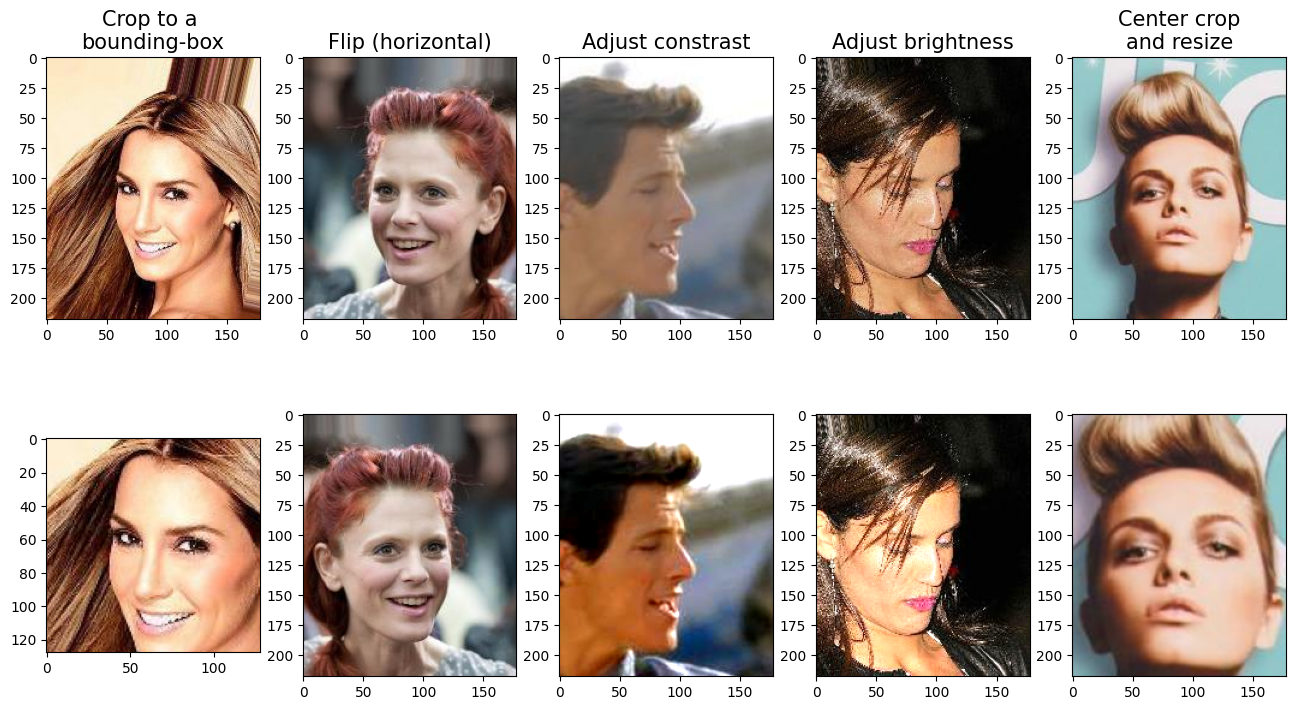

In [ ]:
from torchvision import transforms 

## take 5 examples

fig = plt.figure(figsize=(16, 8.5))

## Column 1: cropping to a bounding-box
ax = fig.add_subplot(2, 5, 1)
img, attr = celeba_train_dataset[0]
ax.set_title('Crop to a \nbounding-box', size=15)
ax.imshow(img)
ax = fig.add_subplot(2, 5, 6)
img_cropped = transforms.functional.crop(img, 50, 20, 128, 128)
ax.imshow(img_cropped)

## Column 2: flipping (horizontally)
ax = fig.add_subplot(2, 5, 2)
img, attr = celeba_train_dataset[1]
ax.set_title('Flip (horizontal)', size=15)
ax.imshow(img)
ax = fig.add_subplot(2, 5, 7)
img_flipped = transforms.functional.hflip(img)
ax.imshow(img_flipped)

## Column 3: adjust contrast
ax = fig.add_subplot(2, 5, 3)
img, attr = celeba_train_dataset[2]
ax.set_title('Adjust constrast', size=15)
ax.imshow(img)
ax = fig.add_subplot(2, 5, 8)
img_adj_contrast = transforms.functional.adjust_contrast(img, contrast_factor=2)
ax.imshow(img_adj_contrast)

## Column 4: adjust brightness
ax = fig.add_subplot(2, 5, 4)
img, attr = celeba_train_dataset[3]
ax.set_title('Adjust brightness', size=15)
ax.imshow(img)
ax = fig.add_subplot(2, 5, 9)
img_adj_brightness = transforms.functional.adjust_brightness(img, brightness_factor=1.3)
ax.imshow(img_adj_brightness)

## Column 5: cropping from image center 
ax = fig.add_subplot(2, 5, 5)
img, attr = celeba_train_dataset[4]
ax.set_title('Center crop\nand resize', size=15)
ax.imshow(img)
ax = fig.add_subplot(2, 5, 10)
img_center_crop = transforms.functional.center_crop(img, [0.7*218, 0.7*178])
img_resized = transforms.functional.resize(img_center_crop, size=(218, 178))
ax.imshow(img_resized)

plt.show()

Figure 14.15: Different image transformations

In Figure 14.15, the original images are shown in the first row and their transformed versions in the second row. Note that for the first transformation (leftmost column), the bounding box is specified by
four numbers: the coordinate of the upper-left corner of the bounding box (here x=20, y=50), and the
width and height of the box (width=128, height=128). Also note that the origin (the coordinates at the
location denoted as (0, 0)) for images loaded by PyTorch (as well as other packages such as imageio)
is the upper-left corner of the image.

The transformations in the previous code block are deterministic. However, all such transformations
can also be randomized, which is recommended for data augmentation during model training. For
example, a random bounding box (where the coordinates of the upper-left corner are selected randomly)
can be cropped from an image, an image can be randomly flipped along either the horizontal
or vertical axes with a probability of 0.5, or the contrast of an image can be changed randomly, where
the contrast_factor is selected at random, but with uniform distribution, from a range of values. In
addition, we can create a pipeline of these transformations.

For example, we can first randomly crop an image, then flip it randomly, and finally, resize it to the
desired size. The code is as follows (since we have random elements, we set the random seed for
reproducibility):

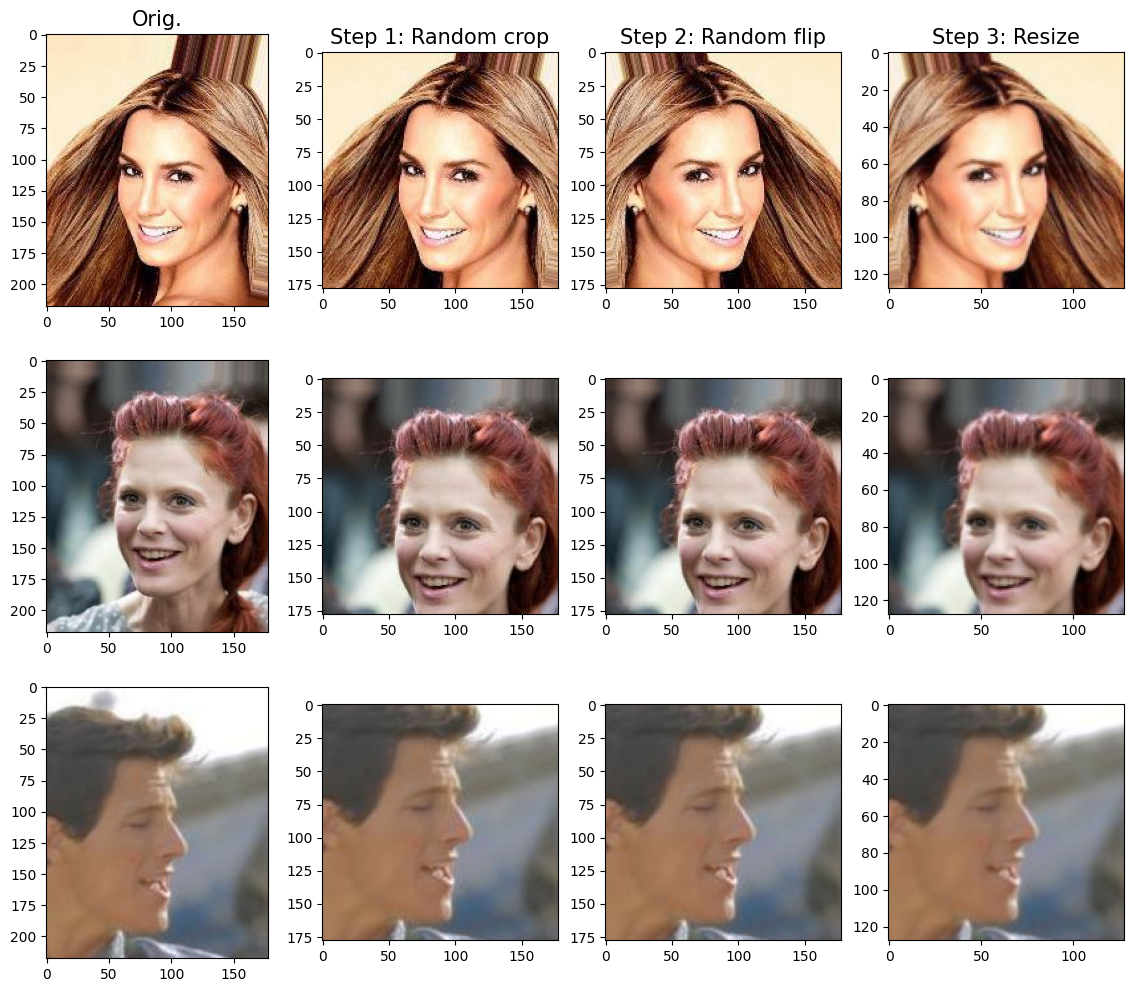

In [ ]:
torch.manual_seed(1)

fig = plt.figure(figsize=(14, 12))

for i, (img, attr) in enumerate(celeba_train_dataset):
    ax = fig.add_subplot(3, 4, i*4+1)
    ax.imshow(img)
    if i == 0:
        ax.set_title('Orig.', size=15)
        
    ax = fig.add_subplot(3, 4, i*4+2)
    img_transform = transforms.Compose([transforms.RandomCrop([178, 178])])
    img_cropped = img_transform(img)
    ax.imshow(img_cropped)
    if i == 0:
        ax.set_title('Step 1: Random crop', size=15)

    ax = fig.add_subplot(3, 4, i*4+3)
    img_transform = transforms.Compose([transforms.RandomHorizontalFlip()])
    img_flip = img_transform(img_cropped)
    ax.imshow(img_flip)
    if i == 0:
        ax.set_title('Step 2: Random flip', size=15)

    ax = fig.add_subplot(3, 4, i*4+4)
    img_resized = transforms.functional.resize(img_flip, size=(128, 128))
    ax.imshow(img_resized)
    if i == 0:
        ax.set_title('Step 3: Resize', size=15)
    
    if i == 2:
        break

plt.show()

Figure 14.16: Random image transformations

Note that each time we iterate through these three examples, we get slightly different images due to
random transformations.
For convenience, we can define transform functions to use this pipeline for data augmentation during dataset loading. In the following code, we will define the function get_smile, which will extract the
smile label from the 'attributes' list

In [32]:
get_smile = lambda attr: attr[31]

We will define the transform_train function that will produce the transformed image (where we will
first randomly crop the image, then flip it randomly, and finally, resize it to the desired size 64×64):

In [ ]:
transform_train = transforms.Compose([
    transforms.RandomCrop([178, 178]),
    transforms.RandomHorizontalFlip(),
    transforms.Resize([64, 64]),
    transforms.ToTensor(),
])

We will only apply data augmentation to the training examples, however, and not to the validation or
test images. The code for the validation or test set is as follows (where we will first simply crop the
image and then resize it to the desired size 64×64)

In [35]:
transform = transforms.Compose([
    transforms.CenterCrop([178, 178]),
    transforms.Resize([64, 64]),
    transforms.ToTensor(),
])

Now, to see data augmentation in action, let’s apply the transform_train function to our training
dataset and iterate over the dataset five times

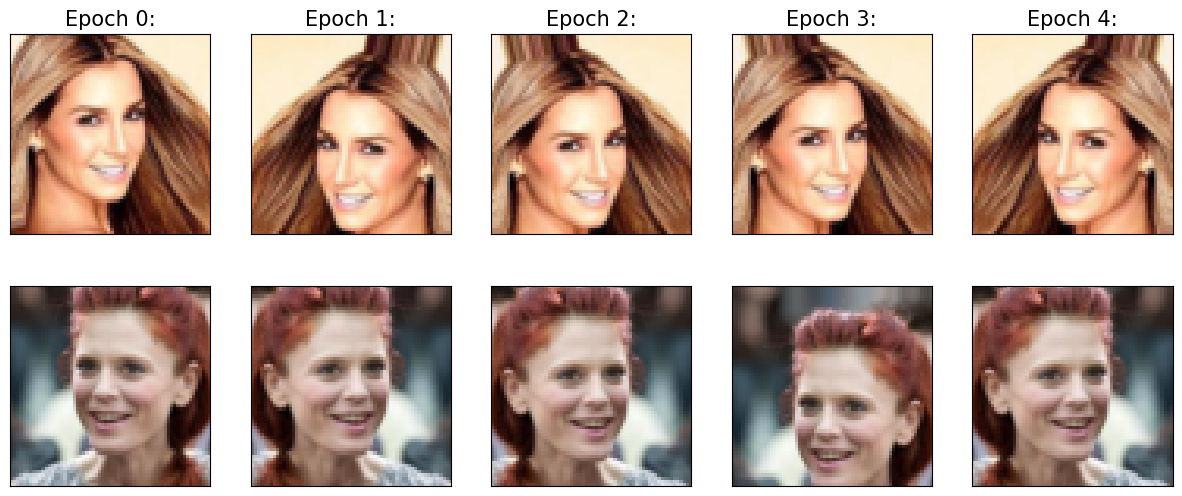

In [36]:
from torch.utils.data import DataLoader

celeba_train_dataset = torchvision.datasets.CelebA(image_path, 
                                                   split='train', 
                                                   target_type='attr', 
                                                   download=False, 
                                                   transform=transform_train,
                                                   target_transform=get_smile)

torch.manual_seed(1)
data_loader = DataLoader(celeba_train_dataset, batch_size=2)

fig = plt.figure(figsize=(15, 6))

num_epochs = 5
for j in range(num_epochs):
    img_batch, label_batch = next(iter(data_loader))
    img = img_batch[0]
    ax = fig.add_subplot(2, 5, j + 1)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'Epoch {j}:', size=15)
    ax.imshow(img.permute(1, 2, 0))

    img = img_batch[1]
    ax = fig.add_subplot(2, 5, j + 6)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(img.permute(1, 2, 0))

plt.show()



Figure 14.17: The result of five image transformations

Figure 14.17 shows the five resulting transformations for data augmentation on two example images.

Next, we will apply the transform function to our validation and test datasets

In [37]:
celeba_valid_dataset = torchvision.datasets.CelebA(image_path, 
                                                   split='valid', 
                                                   target_type='attr', 
                                                   download=False, 
                                                   transform=transform,
                                                   target_transform=get_smile)

celeba_test_dataset = torchvision.datasets.CelebA(image_path, 
                                                   split='test', 
                                                   target_type='attr', 
                                                   download=False, 
                                                   transform=transform,
                                                   target_transform=get_smile)



Furthermore, instead of using all the available training and validation data, we will take a subset of
16,000 training examples and 1,000 examples for validation, as our goal here is to intentionally train
our model with a small dataset

In [38]:
from torch.utils.data import Subset
celeba_train_dataset = Subset(celeba_train_dataset, torch.arange(16000)) 
celeba_valid_dataset = Subset(celeba_valid_dataset, torch.arange(1000)) 
 
print('Train set:', len(celeba_train_dataset))
print('Validation set:', len(celeba_valid_dataset))

Train set: 16000
Validation set: 1000


Now, we can create data loaders for three datasets

In [39]:
batch_size = 32

torch.manual_seed(1)
train_dl = DataLoader(celeba_train_dataset, batch_size, shuffle=True)
valid_dl = DataLoader(celeba_valid_dataset, batch_size, shuffle=False)
test_dl = DataLoader(celeba_test_dataset, batch_size, shuffle=False)

Now that the data loaders are ready, we will develop a CNN model, and train and evaluate it in the
next section.

#### Training a CNN smile classifier

By now, building a model with torch.nn module and training it should be straightforward. The design
of our CNN is as follows: the CNN model receives input images of size 3×64×64 (the images have three
color channels).

The input data goes through four convolutional layers to make 32, 64, 128, and 256 feature maps using
filters with a kernel size of 3×3 and padding of 1 for same padding. The first three convolution layers
are followed by max-pooling, P2×2. Two dropout layers are also included for regularization

In [40]:
import torch.nn as nn

model = nn.Sequential()

model.add_module('conv1', nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1))
model.add_module('relu1', nn.ReLU())        
model.add_module('pool1', nn.MaxPool2d(kernel_size=2))  
model.add_module('dropout1', nn.Dropout(p=0.5)) 

model.add_module('conv2', nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1))
model.add_module('relu2', nn.ReLU())        
model.add_module('pool2', nn.MaxPool2d(kernel_size=2))   
model.add_module('dropout2', nn.Dropout(p=0.5)) 

model.add_module('conv3', nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1))
model.add_module('relu3', nn.ReLU())        
model.add_module('pool3', nn.MaxPool2d(kernel_size=2))   

model.add_module('conv4', nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1))
model.add_module('relu4', nn.ReLU())  


Let’s see the shape of the output feature maps after applying these layers using a toy batch input (four
images arbitrarily)

In [41]:
x = torch.ones((4, 3, 64, 64))
model(x).shape

torch.Size([4, 256, 8, 8])

There are 256 feature maps (or channels) of size 8×8. Now, we can add a fully connected layer to get
to the output layer with a single unit. If we reshape (flatten) the feature maps, the number of input
units to this fully connected layer will be 8 × 8 × 256 = 16,384. Alternatively, let’s consider a new layer,
called global average-pooling, which computes the average of each feature map separately, thereby
reducing the hidden units to 256. We can then add a fully connected layer. Although we have not discussed
global average-pooling explicitly, it is conceptually very similar to other pooling layers. Global
average-pooling can be viewed, in fact, as a special case of average-pooling when the pooling size is
equal to the size of the input feature maps.

To understand this, consider Figure 14.18, showing an example of input feature maps of shape batchsize×8×64×64.
The channels are numbered k =0, 1, ..., 7. The global average-pooling operation calculates
the average of each channel so that the output will have the shape [batchsize×8]. After this, we will
squeeze the output of the global average-pooling layer.

Without squeezing the output, the shape would be [batchsize×8×1×1], as the global average-pooling
would reduce the spatial dimension of 64×64 to 1×1

<img src="https://raw.githubusercontent.com/dewdotninja/mlpi/refs/heads/main/figures/fig14_18.png" width=800 />

Figure 14.18: Input feature maps

Therefore, given that, in our case, the shape of the feature maps prior to this layer is [batchsize×256×8×8],
we expect to get 256 units as output, that is, the shape of the output will be [batchsize×256]. Let’s add
this layer and recompute the output shape to verify that this is true

In [42]:
model.add_module('pool4', nn.AvgPool2d(kernel_size=8)) 
model.add_module('flatten', nn.Flatten()) 

x = torch.ones((4, 3, 64, 64))
model(x).shape


torch.Size([4, 256])

Finally, we can add a fully connected layer to get a single output unit. In this case, we can specify the
activation function to be 'sigmoid'

In [43]:
model.add_module('fc', nn.Linear(256, 1)) 
model.add_module('sigmoid', nn.Sigmoid()) 

In [44]:
x = torch.ones((4, 3, 64, 64))
model(x).shape

torch.Size([4, 1])

In [45]:
model

Sequential(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout1): Dropout(p=0.5, inplace=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout2): Dropout(p=0.5, inplace=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu4): ReLU()
  (pool4): AvgPool2d(kernel_size=8, stride=8, padding=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=256, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

The next step is to create a loss function and optimizer (Adam optimizer again). For a binary classification
with a single probabilistic output, we use BCELoss for the loss function

In [46]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [47]:
# device = torch.device("cuda:0")
device = torch.device("cpu")
model = model.to(device) 

Now we can train the model by defining the following function

In [48]:
def train(model, num_epochs, train_dl, valid_dl):
    loss_hist_train = [0] * num_epochs
    accuracy_hist_train = [0] * num_epochs
    loss_hist_valid = [0] * num_epochs
    accuracy_hist_valid = [0] * num_epochs
    for epoch in range(num_epochs):
        model.train()
        for x_batch, y_batch in train_dl:
            x_batch = x_batch.to(device) 
            y_batch = y_batch.to(device) 
            pred = model(x_batch)[:, 0]
            loss = loss_fn(pred, y_batch.float())
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            loss_hist_train[epoch] += loss.item()*y_batch.size(0)
            is_correct = ((pred>=0.5).float() == y_batch).float()
            accuracy_hist_train[epoch] += is_correct.sum().cpu()

        loss_hist_train[epoch] /= len(train_dl.dataset)
        accuracy_hist_train[epoch] /= len(train_dl.dataset)
        
        model.eval()
        with torch.no_grad():
            for x_batch, y_batch in valid_dl:
                x_batch = x_batch.to(device) 
                y_batch = y_batch.to(device) 
                pred = model(x_batch)[:, 0]
                loss = loss_fn(pred, y_batch.float())
                loss_hist_valid[epoch] += loss.item()*y_batch.size(0) 
                is_correct = ((pred>=0.5).float() == y_batch).float()
                accuracy_hist_valid[epoch] += is_correct.sum().cpu()

        loss_hist_valid[epoch] /= len(valid_dl.dataset)
        accuracy_hist_valid[epoch] /= len(valid_dl.dataset)
        
        print(f'Epoch {epoch+1} accuracy: {accuracy_hist_train[epoch]:.4f} val_accuracy: {accuracy_hist_valid[epoch]:.4f}')
    return loss_hist_train, loss_hist_valid, accuracy_hist_train, accuracy_hist_valid


Next, we will train this CNN model for 30 epochs and use the validation dataset that we created for
monitoring the learning progress

**Warning :** Running the cell below takes more than half an hour on my Mac M1 (no GPU).

In [49]:
torch.manual_seed(1)
num_epochs = 30
hist = train(model, num_epochs, train_dl, valid_dl)

Epoch 1 accuracy: 0.5101 val_accuracy: 0.5140
Epoch 2 accuracy: 0.5307 val_accuracy: 0.5480
Epoch 3 accuracy: 0.5356 val_accuracy: 0.5610
Epoch 4 accuracy: 0.5758 val_accuracy: 0.5930
Epoch 5 accuracy: 0.6081 val_accuracy: 0.6350
Epoch 6 accuracy: 0.6329 val_accuracy: 0.6450
Epoch 7 accuracy: 0.6515 val_accuracy: 0.6620
Epoch 8 accuracy: 0.6636 val_accuracy: 0.6550
Epoch 9 accuracy: 0.6740 val_accuracy: 0.6120
Epoch 10 accuracy: 0.6869 val_accuracy: 0.6800
Epoch 11 accuracy: 0.7038 val_accuracy: 0.7120
Epoch 12 accuracy: 0.7269 val_accuracy: 0.7480
Epoch 13 accuracy: 0.7452 val_accuracy: 0.7850
Epoch 14 accuracy: 0.7746 val_accuracy: 0.7940
Epoch 15 accuracy: 0.8002 val_accuracy: 0.8340
Epoch 16 accuracy: 0.8193 val_accuracy: 0.8470
Epoch 17 accuracy: 0.8264 val_accuracy: 0.8670
Epoch 18 accuracy: 0.8378 val_accuracy: 0.8570
Epoch 19 accuracy: 0.8460 val_accuracy: 0.8720
Epoch 20 accuracy: 0.8504 val_accuracy: 0.8790
Epoch 21 accuracy: 0.8562 val_accuracy: 0.8770
Epoch 22 accuracy: 0.8

Let’s now visualize the learning curve and compare the training and validation loss and accuracies
after each epoch

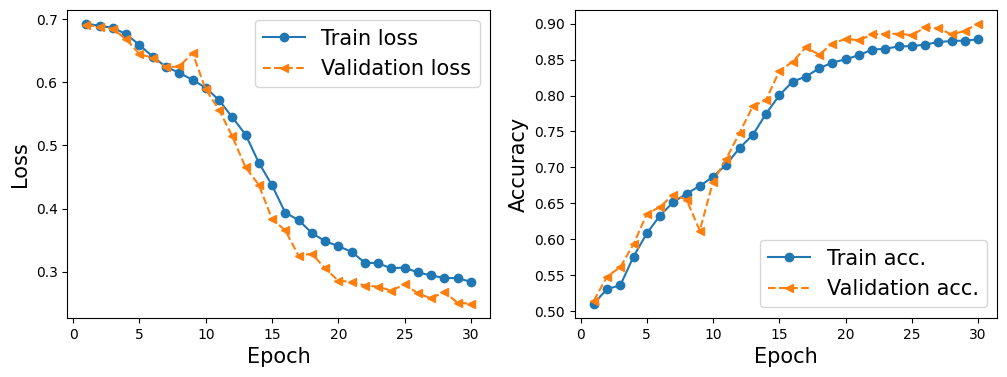

In [50]:
x_arr = np.arange(len(hist[0])) + 1

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 2, 1)
ax.plot(x_arr, hist[0], '-o', label='Train loss')
ax.plot(x_arr, hist[1], '--<', label='Validation loss')
ax.legend(fontsize=15)
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Loss', size=15)

ax = fig.add_subplot(1, 2, 2)
ax.plot(x_arr, hist[2], '-o', label='Train acc.')
ax.plot(x_arr, hist[3], '--<', label='Validation acc.')
ax.legend(fontsize=15)
ax.set_xlabel('Epoch', size=15)
ax.set_ylabel('Accuracy', size=15)

plt.show()

Figure 14.19: A comparison of the training and validation results

Once we are happy with the learning curves, we can evaluate the model on the hold-out test dataset:


In [51]:
accuracy_test = 0

model.eval()
with torch.no_grad():
    for x_batch, y_batch in test_dl:
        x_batch = x_batch.to(device) 
        y_batch = y_batch.to(device) 
        pred = model(x_batch)[:, 0]
        is_correct = ((pred>=0.5).float() == y_batch).float()
        accuracy_test += is_correct.sum().cpu()
 
accuracy_test /= len(test_dl.dataset)
        
print(f'Test accuracy: {accuracy_test:.4f}') 

Test accuracy: 0.8996


Finally, we already know how to get the prediction results on some test examples. In the following
code, we will take a small subset of 10 examples from the last batch of our pre-processed test dataset
(test_dl). Then, we will compute the probabilities of each example being from class 1 (which corresponds
to smile based on the labels provided in CelebA) and visualize the examples along with their
ground truth label and the predicted probabilities

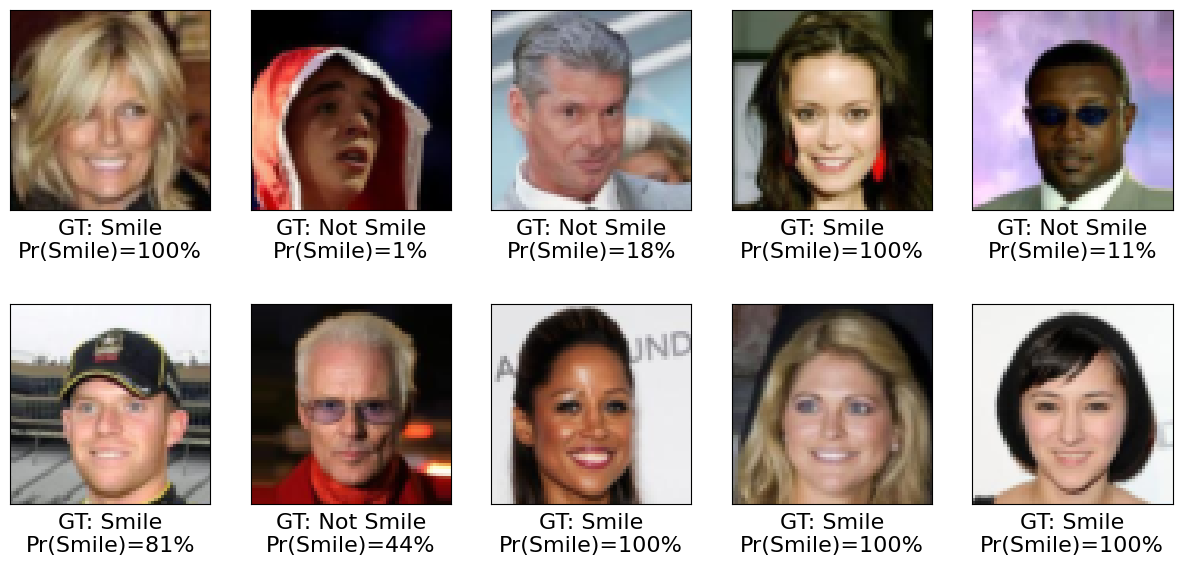

In [52]:
pred = model(x_batch)[:, 0] * 100

fig = plt.figure(figsize=(15, 7))
for j in range(10, 20):
    ax = fig.add_subplot(2, 5, j-10+1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(x_batch[j].cpu().permute(1, 2, 0))
    if y_batch[j] == 1:
        label = 'Smile'
    else:
        label = 'Not Smile'
    ax.text(
        0.5, -0.15, 
        f'GT: {label:s}\nPr(Smile)={pred[j]:.0f}%', 
        size=16, 
        horizontalalignment='center',
        verticalalignment='center', 
        transform=ax.transAxes)

plt.show()

Figure 14.20: Image labels and their probabilities that they belong to class 1
    
In Figure 14.20, you can see 10 example images along with their ground truth labels and the probabilities
that they belong to class 1, smile 

The probabilities of class 1 (that is, smile according to CelebA) are provided below each image. As you
can see, our trained model is completely accurate on this set of 10 test examples.

As an optional exercise, you are encouraged to try using the entire training dataset instead of the small
subset we created. Furthermore, you can change or modify the CNN architecture. For example, you
can change the dropout probabilities and the number of filters in the different convolutional layers.
Also, you could replace the global average-pooling with a fully connected layer. If you are using the
entire training dataset with the CNN architecture we trained in this chapter, you should be able to
achieve above 90 percent accuracy.

### Summary

In this chapter, we learned about CNNs and their main components. We started with the convolution
operation and looked at 1D and 2D implementations. Then, we covered another type of layer that is
found in several common CNN architectures: the subsampling or so-called pooling layers. We primarily
focused on the two most common forms of pooling: max-pooling and average-pooling.

Next, putting all these individual concepts together, we implemented deep CNNs using the torch.nn
module. The first network we implemented was applied to the already familiar MNIST handwritten
digit recognition problem.

Then, we implemented a second CNN on a more complex dataset consisting of face images and trained
the CNN for smile classification. Along the way, you also learned about data augmentation and different
transformations that we can apply to face images using the torchvision.transforms module.

### Related Videos

#### Lectures from top university instructors
<ul>
<li />Deep Learning Specialization by DeepLearningAI (Andrew Ng): <a href="https://youtube.com/playlist?list=PLkDaE6sCZn6Gl29AoE31iwdVwSG-KnDzF&si=4TXwIkUNFp4H9tH0">Course 4 : Convolutional Neural Networks</a> 
<li />MIT 6.S191 (2025): <a href="https://youtu.be/oGpzWAlP5p0?si=voB9BJaFASZqDC9w">Lecture 3 Convolutional Neural Networks for Computer Vision</a>
<li />MIT Machine learning 6.036 (Fall 2020): <a href=https://youtu.be/sFEZ180RvTI?si=l7vCVXeEb5HXGGPF">Lecture 8: Convolutional neural networks</a>
<li />University of Tübingen Machine Learning I : <a href="https://youtu.be/Uf9xJDJt1KA?si=MmRvR78B4ftxPvFF&t=2610">07 - Neural networks and deep learning</a>
</ul>

#### General

<ul>
<li /><a href="https://youtu.be/KuXjwB4LzSA?si=RoIDCDybULhzXeB8">But what is a convolution?</a> by 3Blue1Brown
</ul>


### References

1. S. Raschka, Y. Liu and V. Mirjalili. [Machine Learning with PyTorch 
and Scikit-Learn.](https://sebastianraschka.com/blog/2022/ml-pytorch-book.html) Packt Publishing. 2022. [Github](https://github.com/rasbt/machine-learning-book)  

2. Y. LeCun et.al. Handwritten Digit Recognition with a Back-Propagation Network ,the Neural Information Processing Systems (NeurIPS) conference. 1989.

3. J.B. Springenberg, A. Dosovitskiy, T. Brox and M. Riedmiller. Striving for Simplicity: The All Convolutional Net, ICLR (workshop track), 2015. [pdf](https://arxiv.org/abs/1412.6806).

4. A. Krizhevsky, I. Sutskever, and G. Hinton. ImageNet Classification with Deep Convolutional Neural 
Networks, 2012 [manuscript](https://papers.nips.cc/paper/4824-imagenet-classification-with-deep-convolutional-neural-networks).

5. D. Maturana and S. Scherer. VoxNet: A 3D Convolutional Neural Network for Real-Time Object Recognition.2015 [pdf](https://www.ri.cmu.edu/pub_files/2015/9/voxnet_maturana_scherer_iros15.pdf)

6. I. Loshchilov and F. HutterDecoupled. Weight Decay Regularization. 2019, [link](https://arxiv.org/abs/1711.05101)

7. N. Srivastava, G. Hinton, A. Krizhevsky, I. Sutskever, and R. Salakhutdinov. Dropout: A Simple Way to Prevent Neural 
Networks from Overfitting, Journal of Machine Learning Research 15.1, pages 1929-1958, 2014, [pdf](http://www.jmlr.org/papers/volume15/srivastava14a/srivastava14a.pdf)

8. D. P. Kingma and J.L. Ba. Adam: A Method for Stochastic Optimization. 2014. [link](https://arxiv.org/abs/1412.6980).

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2025</div>